<a href="https://colab.research.google.com/github/kulanigayathree/J26-IT-364/blob/model%2FCoral-reef-health-monitoring/notebooks/C3_Day2_Model_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Component 3 – Day 2: Preprocessing and model training
**Random Forest vs SVM vs XGBoost · spatial cross-validation · preprocessing ablation**

Uses only the Day 1 files in Google Drive (no Earth Engine login needed). Runtime about 5–10 minutes.

| Part | Task |
|---|---|
| 0 | Setup |
| A | Data cleaning, sunglint correction, features, spatial blocks |
| B | 3 models × 3 feature sets, spatial cross-validation |
| C | Final model, classified maps and benthic cover |

Outputs are saved to `coral_c3/results/` and `coral_c3/models/`.

## Part 0 – Setup

In [ ]:
!pip install -q rasterio xgboost
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os, json, time, numpy as np, pandas as pd, matplotlib.pyplot as plt, rasterio, joblib

BASE = '/content/drive/MyDrive/coral_c3'
RES, MOD = f'{BASE}/results', f'{BASE}/models'
os.makedirs(RES, exist_ok=True); os.makedirs(MOD, exist_ok=True)

SITES = ['HKD', 'PGI']
CLASS_NAMES = {11: 'Sand', 12: 'Rubble', 13: 'Rock', 14: 'Seagrass', 15: 'Coral/Algae', 18: 'Microalgal Mats'}
CLASS_COLORS = {11: '#f4e4b0', 12: '#b0a99f', 13: '#5f6b7a', 14: '#3f9c4a', 15: '#ff7f50', 18: '#8b5a2b'}
print(sorted(os.listdir(BASE)))

['ACA_HKD_label.tif', 'ACA_PGI_label.tif', 'HKD_samples.csv', 'PGI_samples.csv', 'S2_HKD_composite.tif', 'S2_PGI_composite.tif', 'class_spectra.png', 'dhw_HKD.csv', 'dhw_PGI.csv', 'dhw_plot.png', 'models', 'results']


**Expected:** the nine Day 1 files are listed.

## Part A – Preprocessing

### A1. Load and clean
1. Remove classes with fewer than 100 samples (Seagrass, 24 samples).
2. Remove bright outliers (B2/B3/B4 > 0.20: residual cloud, whitecaps, surf).

In [ ]:
df = pd.concat([pd.read_csv(f'{BASE}/{s}_samples.csv').assign(site=s) for s in SITES], ignore_index=True)
n0 = len(df)

counts = df['label'].value_counts()
small = [CLASS_NAMES.get(c, c) for c in counts[counts < 100].index]
df = df[df['label'].isin(counts[counts >= 100].index)]
n1 = len(df)

bright = (df[['B2', 'B3', 'B4']] > 0.20).any(axis=1)
df = df[~bright].copy()
n2 = len(df)

xy = np.array([json.loads(g)['coordinates'] for g in df['.geo']])
df['x'], df['y'] = xy[:, 0], xy[:, 1]
df['class_name'] = df['label'].map(CLASS_NAMES)

print(f'Loaded            : {n0}')
print(f'Small classes out : {n0 - n1}  {small}')
print(f'Outliers out      : {n1 - n2}')
print(f'Clean dataset     : {n2}')
print(df.groupby(['site', 'class_name']).size().unstack(fill_value=0))

Loaded            : 2424
Small classes out : 24  ['Seagrass']
Outliers out      : 38
Clean dataset     : 2362
class_name  Coral/Algae  Rock  Rubble  Sand
site                                       
HKD                 300   292     272   300
PGI                 300   300     300   298


**Expected:** about 2,350–2,400 samples in four classes (Coral/Algae, Rock, Rubble, Sand).

### A2. Sunglint correction (Hedley et al., 2005)
NIR (B8) should be close to zero over water, so B8 > 0 mostly indicates sunglint.
For each image, the regression slope of B2/B3/B4 against B8 over optically deep (darkest) water is estimated and removed:

> B_i' = B_i − slope_i × (B8 − min(B8))

Because the parameters are estimated from each image, the same method works for new images in the demo app.

In [ ]:
def read_composite(path):
    with rasterio.open(path) as src:
        arr = src.read().astype('float32')
        profile = src.profile
    arr[arr <= 0] = np.nan          # nodata (-9999) + invalid
    return arr / 10000.0, profile   # bands: B2, B3, B4, B8, B11

def estimate_glint(arr, dark_pct=10):
    b2, b3, b4, b8 = arr[0], arr[1], arr[2], arr[3]
    valid = np.isfinite(b2) & np.isfinite(b3) & np.isfinite(b4) & np.isfinite(b8)
    dark = b3 - b8                    # glint-insensitive brightness → selects deep water, not just low-glint pixels
    deep = valid & (dark <= np.nanpercentile(dark[valid], dark_pct))
    nir = b8[deep]
    g = {'min_nir': float(np.percentile(nir, 1)), 'n_deep': int(deep.sum())}
    for name, b in zip(['B2', 'B3', 'B4'], [b2, b3, b4]):
        g[name] = float(np.clip(np.polyfit(nir, b[deep], 1)[0], 0, 2))
    return g

def make_features(d, g):
    """d: dict/DataFrame with B2,B3,B4,B8 · g: glint params. Returns dict of all features."""
    out = {}
    for b in ['B2', 'B3', 'B4']:
        out[b] = np.asarray(d[b], dtype='float32')
        out[b + 'g'] = np.clip(out[b] - g[b] * (np.asarray(d['B8'], dtype='float32') - g['min_nir']), 1e-4, None)
    out['r23'] = np.log(out['B2g']) - np.log(out['B3g'])   # depth-invariant style log ratios
    out['r24'] = np.log(out['B2g']) - np.log(out['B4g'])
    return out

composites, profiles, glint = {}, {}, {}
for s in SITES:
    composites[s], profiles[s] = read_composite(f'{BASE}/S2_{s}_composite.tif')
    glint[s] = estimate_glint(composites[s])
    print(s, {k: round(v, 4) if isinstance(v, float) else v for k, v in glint[s].items()})
json.dump(glint, open(f'{RES}/glint_params.json', 'w'), indent=2)

HKD {'min_nir': 0.0445, 'n_deep': 4598, 'B2': 0.7753, 'B3': 0.9763, 'B4': 1.0154}
PGI {'min_nir': 0.0258, 'n_deep': 46850, 'B2': 0.62, 'B3': 0.9444, 'B4': 1.0016}


**Expected:** `min_nir`, slopes for B2/B3/B4 (between 0 and 2) and the number of deep-water pixels per site.

### A3. Feature sets (ablation) and spatial blocks

In [ ]:
FEATURE_SETS = {
    'FS1_raw':         ['B2', 'B3', 'B4'],                        # no preprocessing
    'FS2_glint':       ['B2g', 'B3g', 'B4g'],                     # + sunglint correction
    'FS3_glint_ratio': ['B2g', 'B3g', 'B4g', 'r23', 'r24'],       # + depth-invariant log ratios
}

parts = []
for s in SITES:
    d = df[df['site'] == s].copy()
    for k, v in make_features(d, glint[s]).items():
        d[k] = v
    parts.append(d)
df = pd.concat(parts)
all_feats = sorted({f for fs in FEATURE_SETS.values() for f in fs})
df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=all_feats)

# Spatial blocks ~500 m (a random split would put neighbouring pixels in both train and test and inflate accuracy)
size = 500 if df['x'].abs().max() > 180 else 0.0045   # metres or degrees
df['block'] = df['site'] + '_' + (df['x'] // size).astype(int).astype(str) + '_' + (df['y'] // size).astype(int).astype(str)
df.to_csv(f'{RES}/training_dataset_clean.csv', index=False)
print('Rows:', len(df), '| spatial blocks:', df['block'].nunique())
print(df[all_feats].describe().round(4))

Rows: 2362 | spatial blocks: 36
              B2        B2g         B3        B3g         B4        B4g  \
count  2362.0000  2362.0000  2362.0000  2362.0000  2362.0000  2362.0000   
mean      0.0922     0.0751     0.1052     0.0824     0.0771     0.0532   
std       0.0245     0.0164     0.0291     0.0193     0.0313     0.0158   
min       0.0385     0.0289     0.0429     0.0287     0.0258     0.0083   
25%       0.0737     0.0616     0.0854     0.0695     0.0514     0.0402   
50%       0.0869     0.0774     0.0965     0.0833     0.0756     0.0537   
75%       0.1060     0.0864     0.1216     0.0946     0.0938     0.0619   
max       0.1852     0.1280     0.1984     0.1530     0.1951     0.1134   

             r23        r24  
count  2362.0000  2362.0000  
mean     -0.0885     0.3647  
std       0.1086     0.2772  
min      -0.6274    -0.7811  
25%      -0.1512     0.1621  
50%      -0.0843     0.3520  
75%      -0.0287     0.5852  
max       0.5431     1.4983  


**Expected:** at least ~15 spatial blocks. The clean dataset is saved as `results/training_dataset_clean.csv`.

## Part B – Model training and comparison

### B1. 3 models × 3 feature sets, 5-fold spatial cross-validation
All models use the same folds. Metrics: overall accuracy, **macro-F1** (main metric) and Cohen's kappa.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, classification_report, confusion_matrix
from xgboost import XGBClassifier

def get_models():
    return {
        'RandomForest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1),
        'SVM': make_pipeline(StandardScaler(), SVC(C=10, gamma='scale', class_weight='balanced')),
        'XGBoost': XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1, subsample=0.8,
                                 colsample_bytree=0.8, eval_metric='mlogloss', random_state=42, n_jobs=-1),
    }

le = LabelEncoder().fit(df['label'])
y = le.transform(df['label'])
class_labels = [CLASS_NAMES[c] for c in le.classes_]
splits = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(df, y, df['block']))

rows, preds = [], {}
for fs, feats in FEATURE_SETS.items():
    X = df[feats].values
    for name, model in get_models().items():
        t0 = time.perf_counter()
        p = cross_val_predict(model, X, y, cv=splits)
        dt = time.perf_counter() - t0
        preds[(fs, name)] = p
        rows.append({'feature_set': fs, 'model': name, 'accuracy': accuracy_score(y, p),
                     'macro_f1': f1_score(y, p, average='macro'), 'kappa': cohen_kappa_score(y, p),
                     'cv_time_s': round(dt, 1)})
        print(f'{fs:16s} {name:13s} OA={rows[-1]["accuracy"]:.3f}  F1={rows[-1]["macro_f1"]:.3f}  '
              f'kappa={rows[-1]["kappa"]:.3f}  ({dt:.1f}s)')

ablation = pd.DataFrame(rows)
ablation.to_csv(f'{RES}/ablation_results.csv', index=False)
print('\nMacro-F1 table:')
print(ablation.pivot(index='model', columns='feature_set', values='macro_f1').round(3))

FS1_raw          RandomForest  OA=0.461  F1=0.460  kappa=0.281  (7.3s)
FS1_raw          SVM           OA=0.516  F1=0.508  kappa=0.354  (0.9s)
FS1_raw          XGBoost       OA=0.453  F1=0.453  kappa=0.271  (7.1s)
FS2_glint        RandomForest  OA=0.473  F1=0.473  kappa=0.298  (7.4s)
FS2_glint        SVM           OA=0.517  F1=0.510  kappa=0.356  (0.9s)
FS2_glint        XGBoost       OA=0.466  F1=0.465  kappa=0.288  (7.1s)
FS3_glint_ratio  RandomForest  OA=0.461  F1=0.461  kappa=0.281  (11.2s)
FS3_glint_ratio  SVM           OA=0.510  F1=0.507  kappa=0.347  (2.0s)
FS3_glint_ratio  XGBoost       OA=0.440  F1=0.440  kappa=0.254  (5.4s)

Macro-F1 table:
feature_set   FS1_raw  FS2_glint  FS3_glint_ratio
model                                            
RandomForest    0.460      0.473            0.461
SVM             0.508      0.510            0.507
XGBoost         0.453      0.465            0.440


**Result:** nine model/feature-set combinations and the macro-F1 summary table.

### B2. Ablation chart (RQ1: does preprocessing improve accuracy?)

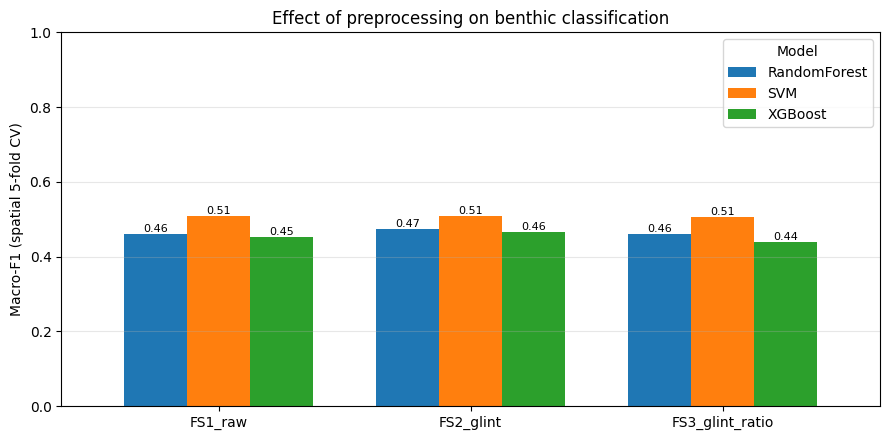

In [ ]:
piv = ablation.pivot(index='feature_set', columns='model', values='macro_f1').loc[list(FEATURE_SETS)]
ax = piv.plot(kind='bar', figsize=(9, 4.5), rot=0, width=0.75)
ax.set_ylabel('Macro-F1 (spatial 5-fold CV)'); ax.set_xlabel('')
ax.set_title('Effect of preprocessing on benthic classification')
ax.set_ylim(0, 1); ax.grid(axis='y', alpha=0.3); ax.legend(title='Model')
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=8)
plt.tight_layout(); plt.savefig(f'{RES}/ablation_macro_f1.png', dpi=150); plt.show()

### B3. Best model and confusion matrix

🏆 Best: SVM with FS2_glint  (Macro-F1 0.510, OA 0.517, kappa 0.356)
       model  accuracy  macro_f1  kappa  cv_time_s
         SVM     0.517     0.510  0.356        0.9
RandomForest     0.473     0.473  0.298        7.4
     XGBoost     0.466     0.465  0.288        7.1

               precision    recall  f1-score   support

        Sand      0.491     0.527     0.508       598
      Rubble      0.507     0.467     0.486       572
        Rock      0.528     0.715     0.607       592
 Coral/Algae      0.554     0.362     0.438       600

    accuracy                          0.517      2362
   macro avg      0.520     0.517     0.510      2362
weighted avg      0.520     0.517     0.510      2362



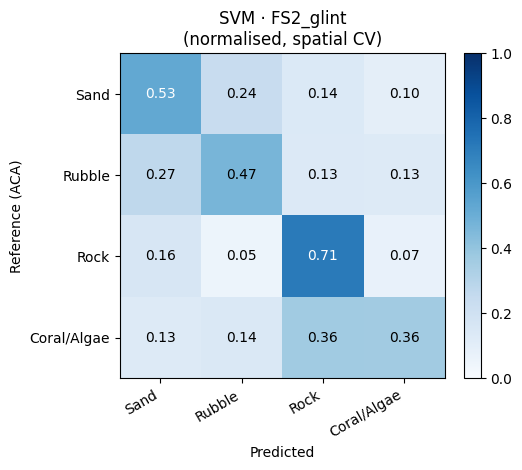

In [ ]:
best = ablation.sort_values('macro_f1', ascending=False).iloc[0]
BEST_FS, BEST_MODEL = best['feature_set'], best['model']
print(f'🏆 Best: {BEST_MODEL} with {BEST_FS}  (Macro-F1 {best.macro_f1:.3f}, OA {best.accuracy:.3f}, kappa {best.kappa:.3f})')

comparison = (ablation[ablation['feature_set'] == BEST_FS]
              .sort_values('macro_f1', ascending=False)
              [['model', 'accuracy', 'macro_f1', 'kappa', 'cv_time_s']])
comparison.to_csv(f'{RES}/model_comparison.csv', index=False)
print(comparison.round(3).to_string(index=False))

p = preds[(BEST_FS, BEST_MODEL)]
print('\n', classification_report(y, p, target_names=class_labels, digits=3))

cm = confusion_matrix(y, p, normalize='true')
fig, ax = plt.subplots(figsize=(5.5, 4.8))
im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(class_labels))); ax.set_xticklabels(class_labels, rotation=30, ha='right')
ax.set_yticks(range(len(class_labels))); ax.set_yticklabels(class_labels)
for i in range(len(cm)):
    for j in range(len(cm)):
        ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', color='white' if cm[i, j] > 0.5 else 'black')
ax.set_xlabel('Predicted'); ax.set_ylabel('Reference (ACA)')
ax.set_title(f'{BEST_MODEL} · {BEST_FS}\n(normalised, spatial CV)')
plt.colorbar(im, fraction=0.046); plt.tight_layout()
plt.savefig(f'{RES}/confusion_matrix.png', dpi=150); plt.show()

The main confusions are Coral/Algae ↔ Rock and Sand ↔ Rubble, which are spectrally similar.

### B4. Cross-site transfer test
Does a model trained on the south-west reef work on the east-coast reef, and vice versa?

In [ ]:
feats = FEATURE_SETS[BEST_FS]
transfer = []
for tr, te in [('HKD', 'PGI'), ('PGI', 'HKD')]:
    m = get_models()[BEST_MODEL]
    a, b = df['site'] == tr, df['site'] == te
    m.fit(df.loc[a, feats].values, le.transform(df.loc[a, 'label']))
    pt = m.predict(df.loc[b, feats].values)
    yt = le.transform(df.loc[b, 'label'])
    transfer.append({'train': tr, 'test': te, 'accuracy': accuracy_score(yt, pt), 'macro_f1': f1_score(yt, pt, average='macro')})
transfer = pd.DataFrame(transfer)
transfer.to_csv(f'{RES}/cross_site_transfer.csv', index=False)
print(transfer.round(3).to_string(index=False))

train test  accuracy  macro_f1
  HKD  PGI     0.415     0.419
  PGI  HKD     0.268     0.188


Transfer performance is lower than within-site performance, indicating that site-specific calibration is needed.

## Part C – Final model and maps

### C1. Final model (all data) and feature importance

In [ ]:
import sklearn, xgboost
final = get_models()[BEST_MODEL].fit(df[feats].values, y)
bundle = {'model': final, 'le': le, 'name': BEST_MODEL, 'feature_set': BEST_FS, 'features': feats,
          'glint_dark_pct': 10, 'class_names': CLASS_NAMES,
          'cv_macro_f1': float(best.macro_f1), 'cv_accuracy': float(best.accuracy),
          'versions': {'sklearn': sklearn.__version__, 'xgboost': xgboost.__version__}}
joblib.dump(bundle, f'{MOD}/best_model.joblib')
print('✅ Saved models/best_model.joblib')
print('Versions (use the same versions for the demo app):', bundle['versions'])

imp = None
if BEST_MODEL == 'RandomForest':
    imp = final.feature_importances_
elif BEST_MODEL == 'XGBoost':
    imp = final.feature_importances_
if imp is not None:
    pd.Series(imp, index=feats).sort_values().plot(kind='barh', figsize=(6, 3), title=f'Feature importance ({BEST_MODEL})')
    plt.tight_layout(); plt.savefig(f'{RES}/feature_importance.png', dpi=150); plt.show()

✅ Saved models/best_model.joblib
Versions (use the same versions for the demo app): {'sklearn': '1.6.1', 'xgboost': '3.4.1'}


The library versions are recorded so that the demo app uses the same versions.

### C2. Classified benthic maps and cover
Pixels are classified only inside the ACA reef extent.
Map agreement includes training pixels and is therefore optimistic; the spatial cross-validation results in B1 are the accuracy estimate.

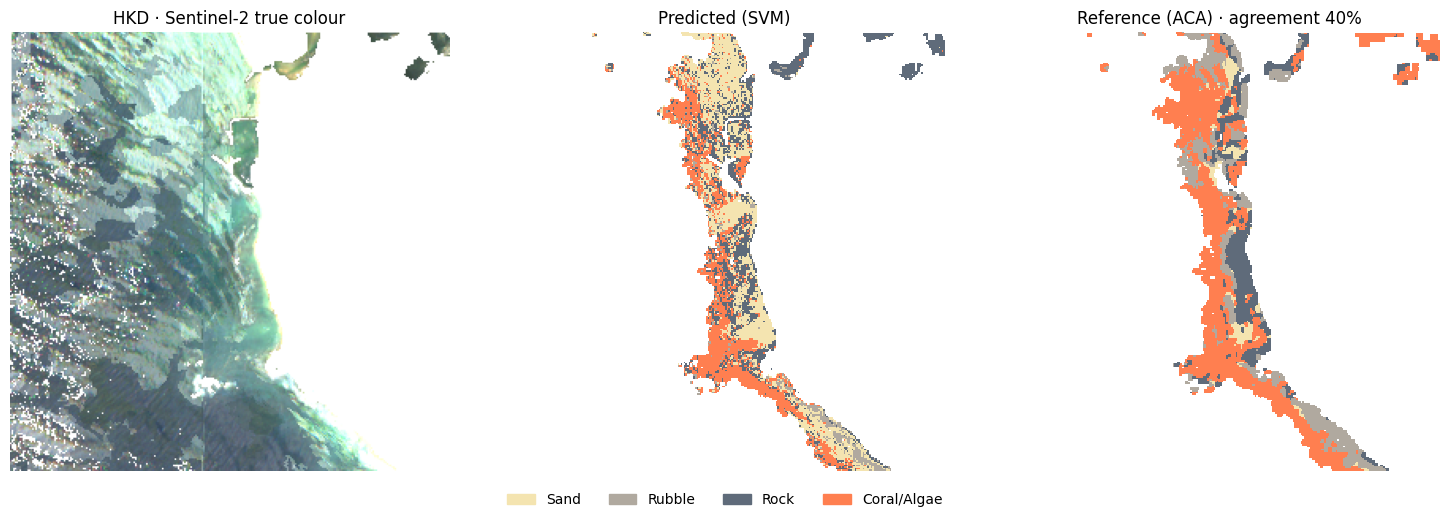

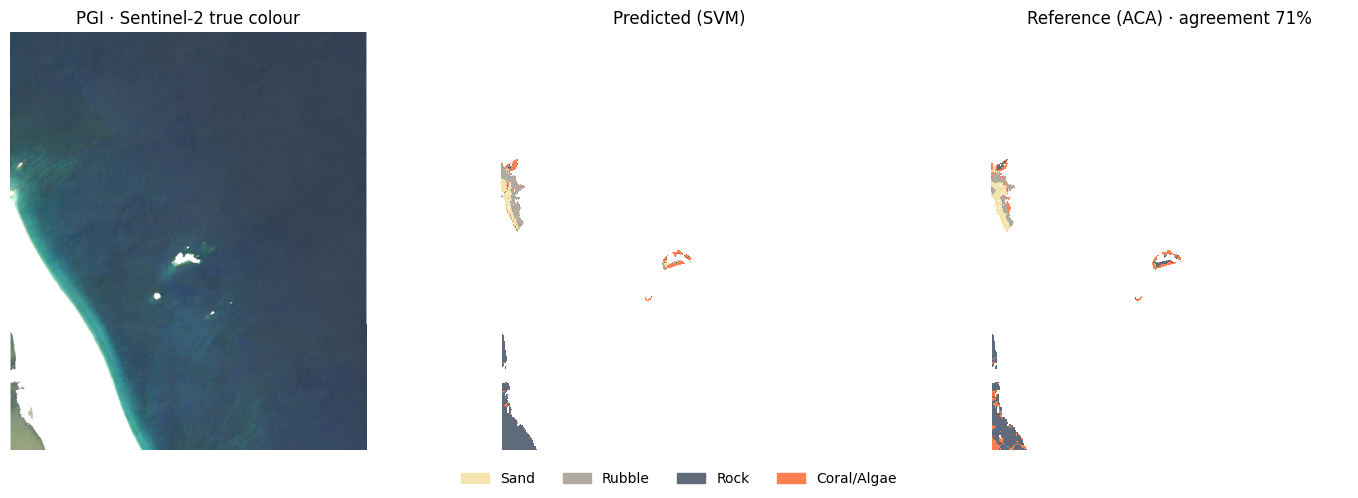

site          HKD   PGI
class                  
Coral/Algae  30.0  11.9
Rock         27.4  52.6
Rubble        6.1  22.1
Sand         36.4  13.5


In [ ]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

codes = list(le.classes_)
cmap = ListedColormap([CLASS_COLORS[c] for c in codes])
norm = BoundaryNorm([c - 0.5 for c in codes] + [codes[-1] + 0.5], cmap.N)
cover_rows = []

for s in SITES:
    arr, prof = composites[s], profiles[s]
    with rasterio.open(f'{BASE}/ACA_{s}_label.tif') as src:
        aca = src.read(1)
    f = make_features({'B2': arr[0], 'B3': arr[1], 'B4': arr[2], 'B8': arr[3]}, glint[s])
    X = np.stack([f[k] for k in feats], axis=-1)
    valid = np.isfinite(X).all(axis=-1) & (aca > 0)
    pred = np.zeros(aca.shape, dtype=np.uint8)
    pred[valid] = le.inverse_transform(final.predict(X[valid]))

    # GeoTIFF output
    out = prof.copy(); out.update(count=1, dtype='uint8', nodata=0)
    with rasterio.open(f'{RES}/classified_{s}.tif', 'w', **out) as dst:
        dst.write(pred, 1)

    agree = (pred[valid] == aca[valid]).mean()
    vals, cnt = np.unique(pred[valid], return_counts=True)
    for v, n in zip(vals, cnt):
        cover_rows.append({'site': s, 'class': CLASS_NAMES[int(v)], 'pixels': int(n),
                           'area_ha': n * 100 / 1e4, 'cover_pct': 100 * n / cnt.sum()})

    rgb = np.nan_to_num(np.clip(np.stack([arr[2], arr[1], arr[0]], -1) / 0.15, 0, 1), nan=1.0)
    fig, axs = plt.subplots(1, 3, figsize=(15, 5))
    axs[0].imshow(rgb); axs[0].set_title(f'{s} · Sentinel-2 true colour')
    axs[1].imshow(np.ma.masked_equal(pred, 0), cmap=cmap, norm=norm, interpolation='nearest')
    axs[1].set_title(f'Predicted ({BEST_MODEL})')
    axs[2].imshow(np.ma.masked_where(~np.isin(aca, codes), aca), cmap=cmap, norm=norm, interpolation='nearest')
    axs[2].set_title(f'Reference (ACA) · agreement {agree:.0%}')
    for a in axs: a.axis('off')
    fig.legend(handles=[Patch(color=CLASS_COLORS[c], label=CLASS_NAMES[c]) for c in codes],
               loc='lower center', ncol=len(codes), frameon=False)
    plt.tight_layout(rect=[0, 0.06, 1, 1]); plt.savefig(f'{RES}/map_{s}.png', dpi=150); plt.show()

cover = pd.DataFrame(cover_rows)
cover.to_csv(f'{RES}/benthic_cover.csv', index=False)
print(cover.pivot(index='class', columns='site', values='cover_pct').round(1))

**Result:** RGB, predicted and reference maps for each site, and the benthic cover table.

### C3. Output files

In [ ]:
for folder in [RES, MOD]:
    print(folder)
    for fn in sorted(os.listdir(folder)):
        print(f'   {fn:32s} {os.path.getsize(os.path.join(folder, fn)) / 1024:8.1f} KB')

/content/drive/MyDrive/coral_c3/results
   ablation_macro_f1.png                45.2 KB
   ablation_results.csv                  0.8 KB
   benthic_cover.csv                     0.3 KB
   classified_HKD.tif                    5.4 KB
   classified_PGI.tif                    7.4 KB
   confusion_matrix.png                 61.0 KB
   cross_site_transfer.csv               0.1 KB
   glint_params.json                     0.3 KB
   map_HKD.png                         583.5 KB
   map_PGI.png                         485.3 KB
   model_comparison.csv                  0.2 KB
   training_dataset_clean.csv          592.7 KB
/content/drive/MyDrive/coral_c3/models
   best_model.joblib                   140.1 KB


**Summary:** best baseline = SVM with sunglint correction (macro-F1 0.51, spatial CV).
Key outputs: `model_comparison.csv`, `ablation_macro_f1.png`, `confusion_matrix.png`, `map_HKD.png`, `map_PGI.png`.